In [2]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import tensorflow as tf
import json
import re
import nltk
import pickle

from datasets import Dataset
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.layers import LSTM
from tensorflow.keras.layers import GRU
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments
)


print("Libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

import torch

print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

Libraries imported successfully!
Pandas version: 2.3.3
NumPy version: 2.1.3
GPU Available: True
GPU Name: Tesla T4


In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/heemalichaudhari/consumer-complaints/Consumer_Complaints.csv


In [3]:

DATA_PATH = "/kaggle/input/datasets/heemalichaudhari/consumer-complaints/Consumer_Complaints.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())


Dataset Shape: (777959, 18)

Columns:
['Date received', 'Product', 'Sub-product', 'Issue', 'Sub-issue', 'Consumer complaint narrative', 'Company public response', 'Company', 'State', 'ZIP code', 'Tags', 'Consumer consent provided?', 'Submitted via', 'Date sent to company', 'Company response to consumer', 'Timely response?', 'Consumer disputed?', 'Complaint ID']

First 5 Rows:


,Date received,Product,Sub-product,Issue,Sub-issue,Consumer complaint narrative,Company public response,Company,State,ZIP code,Tags,Consumer consent provided?,Submitted via,Date sent to company,Company response to consumer,Timely response?,Consumer disputed?,Complaint ID
0,03/21/2017,Credit reporting,NaN,Incorrect information on credit report,Information is not mine,NaN,Company has responded to the consumer and the ...,EXPERIAN DELAWARE GP,TX,77075,Older American,NaN,Phone,03/21/2017,Closed with non-monetary relief,Yes,No,2397100
1,04/19/2017,Debt collection,"Other (i.e. phone, health club, etc.)",Disclosure verification of debt,Not disclosed as an attempt to collect,NaN,NaN,"Security Credit Services, LLC",IL,60643,NaN,NaN,Web,04/20/2017,Closed with explanation,Yes,No,2441777
2,04/19/2017,Credit card,NaN,Other,NaN,NaN,Company has responded to the consumer and the ...,"CITIBANK, N.A.",IL,62025,NaN,NaN,Referral,04/20/2017,Closed with explanation,Yes,No,2441830
3,04/14/2017,Mortgage,Other mortgage,"Loan modification,collection,foreclosure",NaN,NaN,Company believes it acted appropriately as aut...,"Shellpoint Partners, LLC",CA,90305,NaN,NaN,Referral,04/14/2017,Closed with explanation,Yes,No,2436165
4,04/19/2017,Credit card,NaN,Credit determination,NaN,NaN,Company has responded to the consumer and the ...,U.S. BANCORP,LA,70571,NaN,NaN,Postal mail,04/21/2017,Closed with explanation,Yes,No,2441726



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 777959 entries, 0 to 777958
Data columns (total 18 columns):
 #   Column                        Non-Null Count   Dtype 
---  ------                        --------------   ----- 
 0   Date received                 777959 non-null  object
 1   Product                       777959 non-null  object
 2   Sub-product                   542822 non-null  object
 3   Issue                         777959 non-null  object
 4   Sub-issue                     320986 non-null  object
 5   Consumer complaint narrative  157865 non-null  object
 6   Company public response       197884 non-null  object
 7   Company                       777959 non-null  object
 8   State                         772056 non-null  object
 9   ZIP code                      772001 non-null  object
 10  Tags                          109264 non-null  object
 11  Consumer consent provided?    288311 non-null  object
 12  Submitted via                 777959

Dataset after removing missing narratives: (157865, 18)

Number of Products:
12

Product Distribution:
Product
Debt collection            38741
Mortgage                   32000
Credit reporting           30319
Credit card                18276
Bank account or service    14500
Student loan               10176
Consumer Loan               9029
Payday loan                 1695
Money transfers             1437
Prepaid card                1404
Other financial service      272
Virtual currency              16
Name: count, dtype: int64

Product Percentages:
Product
Debt collection            24.54
Mortgage                   20.27
Credit reporting           19.21
Credit card                11.58
Bank account or service     9.19
Student loan                6.45
Consumer Loan               5.72
Payday loan                 1.07
Money transfers             0.91
Prepaid card                0.89
Other financial service     0.17
Virtual currency            0.01
Name: proportion, dtype: float64


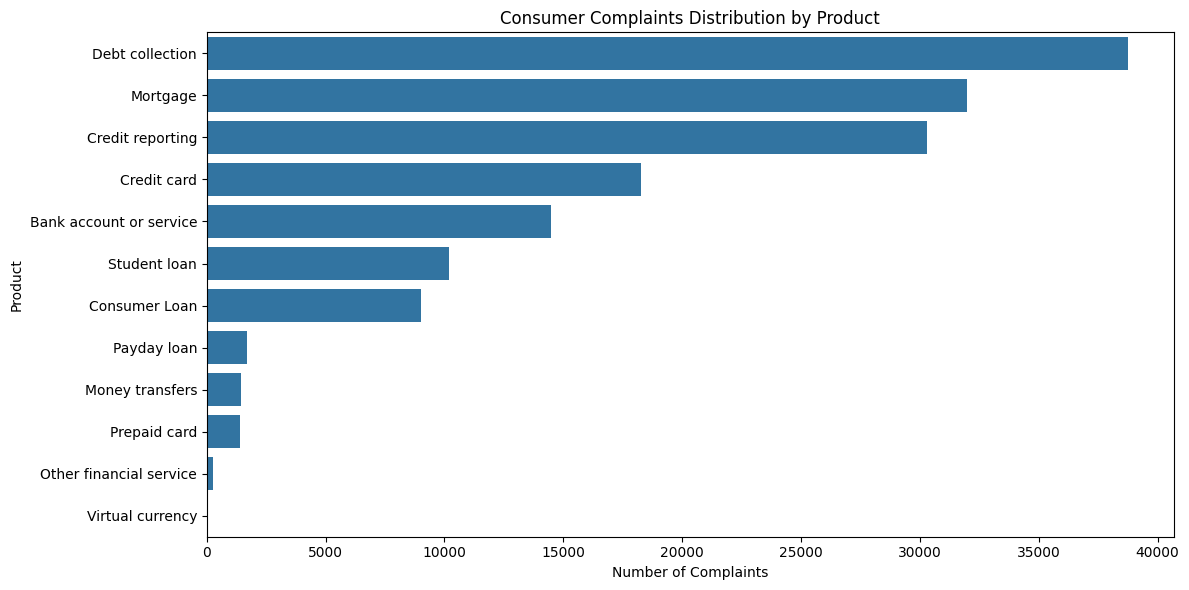


Text Length Statistics:
count    157865.000000
mean        191.030659
std         167.273157
min           1.000000
25%          71.000000
50%         136.000000
75%         255.000000
max        1284.000000
Name: text_length, dtype: float64


In [4]:

df_nlp = df[
    df["Consumer complaint narrative"].notna()
].copy()

df_nlp = df_nlp[
    df_nlp["Consumer complaint narrative"].str.strip() != ""
]

print("Dataset after removing missing narratives:", df_nlp.shape)

print("\nNumber of Products:")
print(df_nlp["Product"].nunique())

print("\nProduct Distribution:")
print(df_nlp["Product"].value_counts())

print("\nProduct Percentages:")
print(
    (df_nlp["Product"].value_counts(normalize=True) * 100)
    .round(2)
)

plt.figure(figsize=(12, 6))

sns.countplot(
    data=df_nlp,
    y="Product",
    order=df_nlp["Product"].value_counts().index
)

plt.title("Consumer Complaints Distribution by Product")
plt.xlabel("Number of Complaints")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

df_nlp["text_length"] = (
    df_nlp["Consumer complaint narrative"].str.split().str.len()
)

print("\nText Length Statistics:")
print(df_nlp["text_length"].describe())


In [5]:

MIN_SAMPLES = 500

class_counts = df_nlp["Product"].value_counts()

valid_classes = class_counts[
    class_counts >= MIN_SAMPLES
].index

df_model = df_nlp[
    df_nlp["Product"].isin(valid_classes)
].copy()

df_model = df_model[
    ["Consumer complaint narrative", "Product"]
].copy()

df_model.columns = ["text", "label"]

df_model = df_model.drop_duplicates(
    subset=["text", "label"]
)

df_model = df_model.reset_index(drop=True)

print("Final Dataset Shape:", df_model.shape)

print("\nNumber of Classes:", df_model["label"].nunique())

print("\nClass Distribution:")
print(df_model["label"].value_counts())

print("\nDuplicate Texts:")
print(df_model["text"].duplicated().sum())

print("\nSample Complaints:")
for i in range(5):
    print(f"\nComplaint {i+1}:")
    print(df_model.iloc[i]["text"][:500])
    print("Label:", df_model.iloc[i]["label"])


Final Dataset Shape: (154706, 2)

Number of Classes: 10

Class Distribution:
label
Debt collection            37739
Mortgage                   31979
Credit reporting           28628
Credit card                18203
Bank account or service    14471
Student loan               10159
Consumer Loan               9000
Payday loan                 1689
Money transfers             1436
Prepaid card                1402
Name: count, dtype: int64

Duplicate Texts:
61

Sample Complaints:

Complaint 1:
Started the refinance of home mortgage process with cash out option on XX/XX/2016. Necessary documents were submitted by XXXX. After initial review, got good faith estimate with loan amount and closing cost. Based on this estimate, a deposit of {$350.00} was made towards appraisal. Appraisal came with lesser amount by {$5000.00}. Agreed to reduce the loan amount to that extent. However, got a revised estimate which was less by {$30000.00} and with additional closing cost towards points etc. In b
Label

In [6]:
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

print("Checking duplicate labels...")

label_conflicts = (
    df_model.groupby("text")["label"]
    .nunique()
)

conflicting_texts = label_conflicts[
    label_conflicts > 1
].index

print("Texts with conflicting labels:", len(conflicting_texts))

df_model = df_model[
    ~df_model["text"].isin(conflicting_texts)
].copy()

df_model = df_model.drop_duplicates(
    subset=["text", "label"]
).reset_index(drop=True)

print("Dataset after duplicate handling:", df_model.shape)

stop_words = set(stopwords.words("english"))

stop_words -= {"no", "not", "nor"}

lemmatizer = WordNetLemmatizer()


def clean_for_sequential(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    words = text.split()

    words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words
    ]

    return " ".join(words)


def clean_for_bert(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    return text


df_model["clean_text"] = df_model["text"].apply(
    clean_for_sequential
)

df_model["bert_text"] = df_model["text"].apply(
    clean_for_bert
)

df_model = df_model[
    (df_model["clean_text"].str.len() > 0) &
    (df_model["bert_text"].str.len() > 0)
].reset_index(drop=True)

print("\nFinal Dataset Shape:", df_model.shape)

print("\nOriginal Text:")
print(df_model["text"].iloc[0][:500])

print("\nSequential Cleaned Text:")
print(df_model["clean_text"].iloc[0][:500])

print("\nBERT Text:")
print(df_model["bert_text"].iloc[0][:500])


[nltk_data] Downloading package stopwords to /usr/share/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /usr/share/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /usr/share/nltk_data...


Checking duplicate labels...
Texts with conflicting labels: 59
Dataset after duplicate handling: (154586, 2)

Final Dataset Shape: (154586, 4)

Original Text:
Started the refinance of home mortgage process with cash out option on XX/XX/2016. Necessary documents were submitted by XXXX. After initial review, got good faith estimate with loan amount and closing cost. Based on this estimate, a deposit of {$350.00} was made towards appraisal. Appraisal came with lesser amount by {$5000.00}. Agreed to reduce the loan amount to that extent. However, got a revised estimate which was less by {$30000.00} and with additional closing cost towards points etc. In b

Sequential Cleaned Text:
started refinance home mortgage process cash option xx xx necessary document submitted xxxx initial review got good faith estimate loan amount closing cost based estimate deposit made towards appraisal appraisal came lesser amount agreed reduce loan amount extent however got revised estimate less additional closi

In [7]:
X = df_model[["clean_text", "bert_text"]]
y = df_model["label"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

print("\nTraining distribution:")
print(y_train.value_counts())

Training samples: 123668
Validation samples: 15459
Testing samples: 15459

Training distribution:
label
Debt collection            30159
Mortgage                   25578
Credit reporting           22876
Credit card                14549
Bank account or service    11573
Student loan                8125
Consumer Loan               7189
Payday loan                 1350
Money transfers             1149
Prepaid card                1120
Name: count, dtype: int64


In [8]:
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_val_encoded = label_encoder.transform(y_val)
y_test_encoded = label_encoder.transform(y_test)

num_classes = len(label_encoder.classes_)

print("Number of classes:", num_classes)
print("\nClass mapping:")

for index, label in enumerate(label_encoder.classes_):
    print(index, ":", label)


Number of classes: 10

Class mapping:
0 : Bank account or service
1 : Consumer Loan
2 : Credit card
3 : Credit reporting
4 : Debt collection
5 : Money transfers
6 : Mortgage
7 : Payday loan
8 : Prepaid card
9 : Student loan


In [9]:
MAX_WORDS = 30000
MAX_LEN = 300

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train["clean_text"])

X_train_seq = tokenizer.texts_to_sequences(X_train["clean_text"])
X_val_seq = tokenizer.texts_to_sequences(X_val["clean_text"])
X_test_seq = tokenizer.texts_to_sequences(X_test["clean_text"])

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_val_pad = pad_sequences(
    X_val_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

vocab_size = min(
    MAX_WORDS,
    len(tokenizer.word_index) + 1
)

print("Vocabulary Size:", vocab_size)
print("Training Shape:", X_train_pad.shape)
print("Validation Shape:", X_val_pad.shape)
print("Testing Shape:", X_test_pad.shape)

Vocabulary Size: 30000
Training Shape: (123668, 300)
Validation Shape: (15459, 300)
Testing Shape: (15459, 300)


In [10]:
classes = np.unique(y_train_encoded)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_encoded
)

class_weights_dict = {
    int(cls): float(weight)
    for cls, weight in zip(classes, class_weights)
}

print("Class Weights:")

for cls, weight in class_weights_dict.items():
    print(label_encoder.classes_[cls], ":", round(weight, 3))


Class Weights:
Bank account or service : 1.069
Consumer Loan : 1.72
Credit card : 0.85
Credit reporting : 0.541
Debt collection : 0.41
Money transfers : 10.763
Mortgage : 0.483
Payday loan : 9.161
Prepaid card : 11.042
Student loan : 1.522


In [11]:
os.makedirs("/kaggle/working/artifacts", exist_ok=True)

with open("/kaggle/working/artifacts/tokenizer.pkl", "wb") as file:
    pickle.dump(tokenizer, file)

with open("/kaggle/working/artifacts/label_encoder.pkl", "wb") as file:
    pickle.dump(label_encoder, file)

print("Preprocessing artifacts saved successfully!")

Preprocessing artifacts saved successfully!


In [35]:

tf.keras.backend.clear_session()

rnn_model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=128,
        input_length=MAX_LEN
    ),
    SimpleRNN(64),
    Dropout(0.3),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(num_classes, activation="softmax")
])

rnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
rnn_model.build(input_shape=(None, MAX_LEN))
rnn_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 300, 128)       │     3,840,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,857,162 (14.71 MB)

 Trainable params: 3,857,162 (14.71 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    ),
    ModelCheckpoint(
        "/kaggle/working/simple_rnn.keras",
        monitor="val_loss",
        save_best_only=True
    )
]


In [15]:

history_rnn = rnn_model.fit(
    X_train_pad,
    y_train_encoded,
    validation_data=(X_val_pad, y_val_encoded),
    epochs=10,
    batch_size=128,
    class_weight=class_weights_dict,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/10
  3/967 ━━━━━━━━━━━━━━━━━━━━ 46s 48ms/step - accuracy: 0.0990 - loss: 2.3099  

I0000 00:00:1793559612.650899     236 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


967/967 ━━━━━━━━━━━━━━━━━━━━ 35s 30ms/step - accuracy: 0.0860 - loss: 2.3116 - val_accuracy: 0.0318 - val_loss: 2.3091 - learning_rate: 0.0010
Epoch 2/10
967/967 ━━━━━━━━━━━━━━━━━━━━ 26s 27ms/step - accuracy: 0.1244 - loss: 2.2890 - val_accuracy: 0.1690 - val_loss: 2.1889 - learning_rate: 0.0010
Epoch 3/10
967/967 ━━━━━━━━━━━━━━━━━━━━ 26s 27ms/step - accuracy: 0.1708 - loss: 2.2386 - val_accuracy: 0.1357 - val_loss: 2.1807 - learning_rate: 0.0010
Epoch 4/10
967/967 ━━━━━━━━━━━━━━━━━━━━ 26s 27ms/step - accuracy: 0.1958 - loss: 2.2355 - val_accuracy: 0.2010 - val_loss: 2.3030 - learning_rate: 0.0010
Epoch 5/10
967/967 ━━━━━━━━━━━━━━━━━━━━ 26s 27ms/step - accuracy: 0.0957 - loss: 2.2896 - val_accuracy: 0.0298 - val_loss: 2.2837 - learning_rate: 0.0010
Epoch 6/10
967/967 ━━━━━━━━━━━━━━━━━━━━ 26s 27ms/step - accuracy: 0.0622 - loss: 2.2771 - val_accuracy: 0.0318 - val_loss: 2.2823 - learning_rate: 5.0000e-04


In [16]:

from sklearn.metrics import classification_report, accuracy_score


rnn_predictions = rnn_model.predict(X_test_pad)

rnn_predicted_classes = np.argmax(
    rnn_predictions,
    axis=1
)

print("SimpleRNN Accuracy:",
      accuracy_score(y_test_encoded, rnn_predicted_classes))

print("\nClassification Report:")

print(
    classification_report(
        y_test_encoded,
        rnn_predicted_classes,
        target_names=label_encoder.classes_
    )
)

484/484 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step
SimpleRNN Accuracy: 0.1349375768160942

Classification Report:
                         precision    recall  f1-score   support

Bank account or service       0.11      0.00      0.00      1447
          Consumer Loan       0.00      0.00      0.00       898
            Credit card       0.12      0.00      0.01      1818
       Credit reporting       0.00      0.00      0.00      2860
        Debt collection       0.00      0.00      0.00      3770
        Money transfers       0.01      0.03      0.01       144
               Mortgage       0.66      0.61      0.63      3198
            Payday loan       0.00      0.00      0.00       168
           Prepaid card       0.01      0.94      0.02       140
           Student loan       0.00      0.00      0.00      1016

               accuracy                           0.13     15459
              macro avg       0.09      0.16      0.07     15459
           weighted avg       0.16      0.13     

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Training Accuracy: 0.062206875532865524
Validation Accuracy: 0.03176143392920494

Training Loss: 2.2770848274230957
Validation Loss: 2.2822725772857666


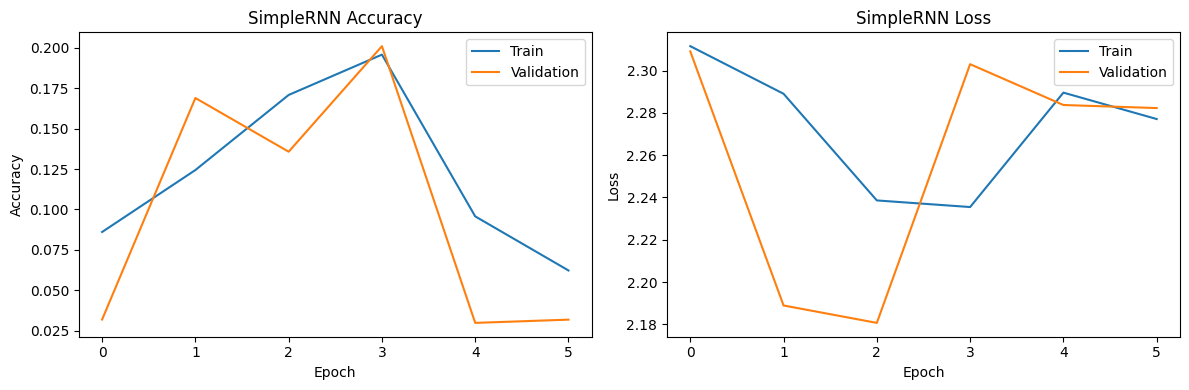

In [17]:

print("Training Accuracy:", history_rnn.history["accuracy"][-1])
print("Validation Accuracy:", history_rnn.history["val_accuracy"][-1])

print("\nTraining Loss:", history_rnn.history["loss"][-1])
print("Validation Loss:", history_rnn.history["val_loss"][-1])

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_rnn.history["accuracy"], label="Train")
plt.plot(history_rnn.history["val_accuracy"], label="Validation")
plt.title("SimpleRNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_rnn.history["loss"], label="Train")
plt.plot(history_rnn.history["val_loss"], label="Validation")
plt.title("SimpleRNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [18]:

print("Number of unique predictions:",
      len(np.unique(rnn_predicted_classes)))

print("\nPredicted Class Distribution:")

print(
    pd.Series(
        label_encoder.inverse_transform(rnn_predicted_classes)
    ).value_counts()
)

print("\nActual Test Distribution:")

print(
    pd.Series(
        label_encoder.inverse_transform(y_test_encoded)
    ).value_counts()
)

print("\nClass Weights:")
print(class_weights_dict)

print("\nLast 5 Training Accuracies:")
print(history_rnn.history["accuracy"][-5:])

print("\nLast 5 Validation Accuracies:")
print(history_rnn.history["val_accuracy"][-5:])


Number of unique predictions: 5

Predicted Class Distribution:
Prepaid card               12016
Mortgage                    2917
Money transfers              424
Credit card                   75
Bank account or service       27
Name: count, dtype: int64

Actual Test Distribution:
Debt collection            3770
Mortgage                   3198
Credit reporting           2860
Credit card                1818
Bank account or service    1447
Student loan               1016
Consumer Loan               898
Payday loan                 168
Money transfers             144
Prepaid card                140
Name: count, dtype: int64

Class Weights:
{0: 1.068590685215588, 1: 1.7202392544164695, 2: 0.8500103099869407, 3: 0.5406015037593985, 4: 0.4100533837328824, 5: 10.763098346388164, 6: 0.4834936273359919, 7: 9.160592592592593, 8: 11.041785714285714, 9: 1.5220676923076923}

Last 5 Training Accuracies:
[0.12437332421541214, 0.17084452509880066, 0.1958145946264267, 0.09568360447883606, 0.0622068755328

In [19]:

stable_class_weights = {
    cls: min(weight, 3.0)
    for cls, weight in class_weights_dict.items()
}

print("Updated Class Weights:")

for cls, weight in stable_class_weights.items():
    print(
        label_encoder.classes_[cls],
        ":",
        round(weight, 3)
    )


Updated Class Weights:
Bank account or service : 1.069
Consumer Loan : 1.72
Credit card : 0.85
Credit reporting : 0.541
Debt collection : 0.41
Money transfers : 3.0
Mortgage : 0.483
Payday loan : 3.0
Prepaid card : 3.0
Student loan : 1.522


In [20]:
tf.keras.backend.clear_session()

rnn_model_v2 = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=128,
        mask_zero=True
    ),
    SimpleRNN(
        64,
        dropout=0.2,
        recurrent_dropout=0.0
    ),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(num_classes, activation="softmax")
])

rnn_model_v2.compile(
    optimizer=Adam(
        learning_rate=0.0003,
        clipnorm=1.0
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
rnn_model_v2.build(input_shape=(None, MAX_LEN))
rnn_model_v2.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [21]:
callbacks_v2 = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    ),
    ModelCheckpoint(
        "/kaggle/working/simple_rnn_v2.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history_rnn_v2 = rnn_model_v2.fit(
    X_train_pad,
    y_train_encoded,
    validation_data=(X_val_pad, y_val_encoded),
    epochs=10,
    batch_size=128,
    class_weight=stable_class_weights,
    callbacks=callbacks_v2,
    verbose=1
)


Epoch 1/10
967/967 ━━━━━━━━━━━━━━━━━━━━ 35s 32ms/step - accuracy: 0.4009 - loss: 1.3238 - val_accuracy: 0.6707 - val_loss: 1.0773 - learning_rate: 3.0000e-04
Epoch 2/10
967/967 ━━━━━━━━━━━━━━━━━━━━ 27s 28ms/step - accuracy: 0.6867 - loss: 0.9040 - val_accuracy: 0.7515 - val_loss: 0.8577 - learning_rate: 3.0000e-04
Epoch 3/10
967/967 ━━━━━━━━━━━━━━━━━━━━ 27s 28ms/step - accuracy: 0.7804 - loss: 0.7192 - val_accuracy: 0.7799 - val_loss: 0.7879 - learning_rate: 3.0000e-04
Epoch 4/10
967/967 ━━━━━━━━━━━━━━━━━━━━ 27s 28ms/step - accuracy: 0.8121 - loss: 0.6255 - val_accuracy: 0.8130 - val_loss: 0.6906 - learning_rate: 3.0000e-04
Epoch 5/10
967/967 ━━━━━━━━━━━━━━━━━━━━ 27s 28ms/step - accuracy: 0.8254 - loss: 0.5702 - val_accuracy: 0.8156 - val_loss: 0.6640 - learning_rate: 3.0000e-04
Epoch 6/10
967/967 ━━━━━━━━━━━━━━━━━━━━ 27s 27ms/step - accuracy: 0.8326 - loss: 0.5329 - val_accuracy: 0.8021 - val_loss: 0.7103 - learning_rate: 3.0000e-04
Epoch 7/10
967/967 ━━━━━━━━━━━━━━━━━━━━ 27s 27ms/ste

In [22]:

callbacks_v2 = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    ),
    ModelCheckpoint(
        "/kaggle/working/simple_rnn_v2.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history_rnn_v2 = rnn_model_v2.fit(
    X_train_pad,
    y_train_encoded,
    validation_data=(X_val_pad, y_val_encoded),
    epochs=10,
    batch_size=128,
    class_weight=stable_class_weights,
    callbacks=callbacks_v2,
    verbose=1
)


Epoch 1/10
967/967 ━━━━━━━━━━━━━━━━━━━━ 27s 28ms/step - accuracy: 0.8751 - loss: 0.3796 - val_accuracy: 0.8308 - val_loss: 0.6057 - learning_rate: 7.5000e-05
Epoch 2/10
967/967 ━━━━━━━━━━━━━━━━━━━━ 27s 27ms/step - accuracy: 0.8785 - loss: 0.3626 - val_accuracy: 0.8312 - val_loss: 0.6071 - learning_rate: 7.5000e-05
Epoch 3/10
967/967 ━━━━━━━━━━━━━━━━━━━━ 27s 27ms/step - accuracy: 0.8823 - loss: 0.3477 - val_accuracy: 0.8317 - val_loss: 0.6094 - learning_rate: 7.5000e-05
Epoch 4/10
967/967 ━━━━━━━━━━━━━━━━━━━━ 27s 28ms/step - accuracy: 0.8880 - loss: 0.3311 - val_accuracy: 0.8360 - val_loss: 0.5958 - learning_rate: 3.7500e-05
Epoch 5/10
967/967 ━━━━━━━━━━━━━━━━━━━━ 26s 27ms/step - accuracy: 0.8890 - loss: 0.3238 - val_accuracy: 0.8347 - val_loss: 0.6001 - learning_rate: 3.7500e-05
Epoch 6/10
967/967 ━━━━━━━━━━━━━━━━━━━━ 27s 28ms/step - accuracy: 0.8916 - loss: 0.3157 - val_accuracy: 0.8365 - val_loss: 0.5948 - learning_rate: 3.7500e-05
Epoch 7/10
967/967 ━━━━━━━━━━━━━━━━━━━━ 27s 27ms/ste

In [23]:
rnn_v2_predictions = rnn_model_v2.predict(X_test_pad)

rnn_v2_classes = np.argmax(
    rnn_v2_predictions,
    axis=1
)

print("SimpleRNN V2 Accuracy:",
      accuracy_score(y_test_encoded, rnn_v2_classes))

print("\nClassification Report:")

print(
    classification_report(
        y_test_encoded,
        rnn_v2_classes,
        target_names=label_encoder.classes_
    )
)

print("\nPredicted Distribution:")

print(
    pd.Series(
        label_encoder.inverse_transform(rnn_v2_classes)
    ).value_counts()
)

484/484 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step
SimpleRNN V2 Accuracy: 0.8340125493240184

Classification Report:
                         precision    recall  f1-score   support

Bank account or service       0.83      0.77      0.80      1447
          Consumer Loan       0.60      0.76      0.67       898
            Credit card       0.80      0.81      0.80      1818
       Credit reporting       0.86      0.86      0.86      2860
        Debt collection       0.87      0.80      0.83      3770
        Money transfers       0.47      0.63      0.54       144
               Mortgage       0.94      0.94      0.94      3198
            Payday loan       0.38      0.42      0.40       168
           Prepaid card       0.56      0.73      0.63       140
           Student loan       0.85      0.88      0.86      1016

               accuracy                           0.83     15459
              macro avg       0.72      0.76      0.73     15459
           weighted avg       0.84      0.83  

In [24]:
simple_rnn_results = {
    "Model": "SimpleRNN",
    "Accuracy": float(accuracy_score(
        y_test_encoded,
        rnn_v2_classes
    )),
    "Macro Precision": 0.72,
    "Macro Recall": 0.76,
    "Macro F1": 0.73,
    "Weighted F1": 0.84
}

with open(
    "/kaggle/working/simple_rnn_results.json",
    "w"
) as file:
    json.dump(simple_rnn_results, file, indent=4)

print(simple_rnn_results)

{'Model': 'SimpleRNN', 'Accuracy': 0.8340125493240184, 'Macro Precision': 0.72, 'Macro Recall': 0.76, 'Macro F1': 0.73, 'Weighted F1': 0.84}


In [31]:
tf.keras.backend.clear_session()

lstm_model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=128,
        mask_zero=True
    ),
    LSTM(
        64,
        dropout=0.2,
        recurrent_dropout=0.0
    ),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(num_classes, activation="softmax")
])

lstm_model.compile(
    optimizer=Adam(
        learning_rate=0.0003,
        clipnorm=1.0
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
lstm_model.build(input_shape=(None, MAX_LEN))

lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 300, 128)       │     3,840,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,894,218 (14.86 MB)

 Trainable params: 3,894,218 (14.86 MB)

 Non-trainable params: 0 (0.00 B)

In [26]:
lstm_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    ),
    ModelCheckpoint(
        "/kaggle/working/lstm.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history_lstm = lstm_model.fit(
    X_train_pad,
    y_train_encoded,
    validation_data=(X_val_pad, y_val_encoded),
    epochs=10,
    batch_size=128,
    class_weight=stable_class_weights,
    callbacks=lstm_callbacks,
    verbose=1
)

Epoch 1/10
967/967 ━━━━━━━━━━━━━━━━━━━━ 25s 19ms/step - accuracy: 0.5716 - loss: 1.1512 - val_accuracy: 0.7771 - val_loss: 0.7934 - learning_rate: 3.0000e-04
Epoch 2/10
967/967 ━━━━━━━━━━━━━━━━━━━━ 18s 19ms/step - accuracy: 0.7920 - loss: 0.7102 - val_accuracy: 0.8099 - val_loss: 0.7109 - learning_rate: 3.0000e-04
Epoch 3/10
967/967 ━━━━━━━━━━━━━━━━━━━━ 18s 19ms/step - accuracy: 0.8222 - loss: 0.5848 - val_accuracy: 0.8290 - val_loss: 0.6100 - learning_rate: 3.0000e-04
Epoch 4/10
967/967 ━━━━━━━━━━━━━━━━━━━━ 18s 19ms/step - accuracy: 0.8376 - loss: 0.5140 - val_accuracy: 0.8275 - val_loss: 0.6058 - learning_rate: 3.0000e-04
Epoch 5/10
967/967 ━━━━━━━━━━━━━━━━━━━━ 18s 19ms/step - accuracy: 0.8510 - loss: 0.4645 - val_accuracy: 0.8316 - val_loss: 0.5823 - learning_rate: 3.0000e-04
Epoch 6/10
967/967 ━━━━━━━━━━━━━━━━━━━━ 18s 19ms/step - accuracy: 0.8609 - loss: 0.4311 - val_accuracy: 0.8203 - val_loss: 0.6254 - learning_rate: 3.0000e-04
Epoch 7/10
967/967 ━━━━━━━━━━━━━━━━━━━━ 18s 18ms/ste

In [27]:
lstm_predictions = lstm_model.predict(X_test_pad)

lstm_predicted_classes = np.argmax(
    lstm_predictions,
    axis=1
)

print("LSTM Accuracy:",
      accuracy_score(y_test_encoded, lstm_predicted_classes))

print("\nClassification Report:")

print(
    classification_report(
        y_test_encoded,
        lstm_predicted_classes,
        target_names=label_encoder.classes_
    )
)

484/484 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step
LSTM Accuracy: 0.8444271945145223

Classification Report:
                         precision    recall  f1-score   support

Bank account or service       0.84      0.77      0.80      1447
          Consumer Loan       0.66      0.71      0.69       898
            Credit card       0.79      0.83      0.81      1818
       Credit reporting       0.88      0.87      0.87      2860
        Debt collection       0.87      0.82      0.84      3770
        Money transfers       0.66      0.66      0.66       144
               Mortgage       0.94      0.94      0.94      3198
            Payday loan       0.41      0.63      0.49       168
           Prepaid card       0.59      0.66      0.62       140
           Student loan       0.84      0.90      0.87      1016

               accuracy                           0.84     15459
              macro avg       0.75      0.78      0.76     15459
           weighted avg       0.85      0.84      0.85

In [30]:
tf.keras.backend.clear_session()

gru_model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=128, mask_zero=True),
    GRU(64, dropout=0.2, recurrent_dropout=0.0),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(num_classes, activation="softmax")
])

gru_model.compile(
    optimizer=Adam(learning_rate=0.0003, clipnorm=1.0),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

gru_model.build(input_shape=(None, MAX_LEN))

gru_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 300, 128)       │     3,840,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        37,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,882,058 (14.81 MB)

 Trainable params: 3,882,058 (14.81 MB)

 Non-trainable params: 0 (0.00 B)

In [36]:
gru_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    ),
    ModelCheckpoint(
        "/kaggle/working/gru.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history_gru = gru_model.fit(
    X_train_pad,
    y_train_encoded,
    validation_data=(X_val_pad, y_val_encoded),
    epochs=10,
    batch_size=128,
    class_weight=stable_class_weights,
    callbacks=gru_callbacks,
    verbose=1
)

Epoch 1/10
967/967 ━━━━━━━━━━━━━━━━━━━━ 20s 19ms/step - accuracy: 0.5061 - loss: 1.2278 - val_accuracy: 0.7620 - val_loss: 0.8377 - learning_rate: 3.0000e-04
Epoch 2/10
967/967 ━━━━━━━━━━━━━━━━━━━━ 18s 19ms/step - accuracy: 0.7851 - loss: 0.7154 - val_accuracy: 0.8171 - val_loss: 0.6368 - learning_rate: 3.0000e-04
Epoch 3/10
967/967 ━━━━━━━━━━━━━━━━━━━━ 18s 18ms/step - accuracy: 0.8246 - loss: 0.5625 - val_accuracy: 0.8305 - val_loss: 0.5769 - learning_rate: 3.0000e-04
Epoch 4/10
967/967 ━━━━━━━━━━━━━━━━━━━━ 18s 18ms/step - accuracy: 0.8403 - loss: 0.4900 - val_accuracy: 0.8394 - val_loss: 0.5384 - learning_rate: 3.0000e-04
Epoch 5/10
967/967 ━━━━━━━━━━━━━━━━━━━━ 18s 18ms/step - accuracy: 0.8536 - loss: 0.4400 - val_accuracy: 0.8401 - val_loss: 0.5332 - learning_rate: 3.0000e-04
Epoch 6/10
967/967 ━━━━━━━━━━━━━━━━━━━━ 18s 18ms/step - accuracy: 0.8625 - loss: 0.4008 - val_accuracy: 0.8355 - val_loss: 0.5507 - learning_rate: 3.0000e-04
Epoch 7/10
967/967 ━━━━━━━━━━━━━━━━━━━━ 18s 18ms/ste

In [37]:
gru_predictions = gru_model.predict(X_test_pad)

gru_predicted_classes = np.argmax(gru_predictions, axis=1)

print("GRU Accuracy:", accuracy_score(y_test_encoded, gru_predicted_classes))

print(classification_report(
    y_test_encoded,
    gru_predicted_classes,
    target_names=label_encoder.classes_
))

484/484 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step
GRU Accuracy: 0.8362119153890938
                         precision    recall  f1-score   support

Bank account or service       0.86      0.76      0.81      1447
          Consumer Loan       0.65      0.71      0.68       898
            Credit card       0.79      0.81      0.80      1818
       Credit reporting       0.86      0.86      0.86      2860
        Debt collection       0.86      0.81      0.83      3770
        Money transfers       0.47      0.69      0.56       144
               Mortgage       0.94      0.93      0.94      3198
            Payday loan       0.40      0.64      0.49       168
           Prepaid card       0.64      0.62      0.63       140
           Student loan       0.80      0.92      0.85      1016

               accuracy                           0.84     15459
              macro avg       0.73      0.77      0.75     15459
           weighted avg       0.84      0.84      0.84     15459



In [39]:
print("SimpleRNN V2:", rnn_model.count_params())
print("LSTM:", lstm_model.count_params())
print("GRU:", gru_model.count_params())

SimpleRNN V2: 3857162
LSTM: 3894218
GRU: 3882058


In [42]:
MODEL_NAME = "distilbert-base-uncased"
MAX_LENGTH = 256

bert_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

bert_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=num_classes
)

print("Number of classes:", num_classes)
print("Model parameters:", bert_model.num_parameters())

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Number of classes: 10
Model parameters: 66961162


In [43]:
train_dataset = Dataset.from_dict({
    "text": X_train["bert_text"].astype(str).tolist(),
    "labels": y_train_encoded.tolist()
})

val_dataset = Dataset.from_dict({
    "text": X_val["bert_text"].astype(str).tolist(),
    "labels": y_val_encoded.tolist()
})

test_dataset = Dataset.from_dict({
    "text": X_test["bert_text"].astype(str).tolist(),
    "labels": y_test_encoded.tolist()
})

def tokenize_data(batch):
    return bert_tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LENGTH
    )

train_dataset = train_dataset.map(
    tokenize_data,
    batched=True,
    remove_columns=["text"]
)

val_dataset = val_dataset.map(
    tokenize_data,
    batched=True,
    remove_columns=["text"]
)

test_dataset = test_dataset.map(
    tokenize_data,
    batched=True,
    remove_columns=["text"]
)

data_collator = DataCollatorWithPadding(
    tokenizer=bert_tokenizer
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))

Map:   0%|          | 0/123668 [00:00<?, ? examples/s]

Map:   0%|          | 0/15459 [00:00<?, ? examples/s]

Map:   0%|          | 0/15459 [00:00<?, ? examples/s]

Training samples: 123668
Validation samples: 15459
Testing samples: 15459


In [44]:
def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    predictions = np.argmax(predictions, axis=1)

    precision, recall, macro_f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="macro",
        zero_division=0
    )

    weighted_f1 = precision_recall_fscore_support(
        labels,
        predictions,
        average="weighted",
        zero_division=0
    )[2]

    accuracy = accuracy_score(labels, predictions)

    return {
        "accuracy": accuracy,
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1
    }

In [45]:
training_args = TrainingArguments(
    output_dir="/kaggle/working/distilbert_results",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=2,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_macro_f1",
    greater_is_better=True,
    save_total_limit=1,
    fp16=torch.cuda.is_available(),
    logging_steps=100,
    report_to="none"
)

bert_trainer = Trainer(
    model=bert_model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    processing_class=bert_tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

bert_training_history = bert_trainer.train()

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
1,0.809870,0.761687,0.880975,0.821608,0.815977,0.816540,0.879843
2,0.660700,0.715645,0.887638,0.833671,0.821365,0.826088,0.886997


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [46]:
bert_results = bert_trainer.predict(test_dataset)

bert_predictions = np.argmax(
    bert_results.predictions,
    axis=1
)

print("DistilBERT Results:")
print(classification_report(
    y_test_encoded,
    bert_predictions,
    target_names=label_encoder.classes_,
    zero_division=0
))

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


DistilBERT Results:
                         precision    recall  f1-score   support

Bank account or service       0.88      0.82      0.85      1447
          Consumer Loan       0.76      0.73      0.74       898
            Credit card       0.85      0.88      0.86      1818
       Credit reporting       0.92      0.91      0.91      2860
        Debt collection       0.87      0.88      0.88      3770
        Money transfers       0.70      0.65      0.67       144
               Mortgage       0.95      0.96      0.95      3198
            Payday loan       0.68      0.55      0.61       168
           Prepaid card       0.75      0.82      0.78       140
           Student loan       0.91      0.92      0.92      1016

               accuracy                           0.89     15459
              macro avg       0.83      0.81      0.82     15459
           weighted avg       0.88      0.89      0.88     15459



In [47]:
bert_trainer.save_model("/kaggle/working/distilbert_model")
bert_tokenizer.save_pretrained("/kaggle/working/distilbert_model")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('/kaggle/working/distilbert_model/tokenizer_config.json',
 '/kaggle/working/distilbert_model/tokenizer.json')

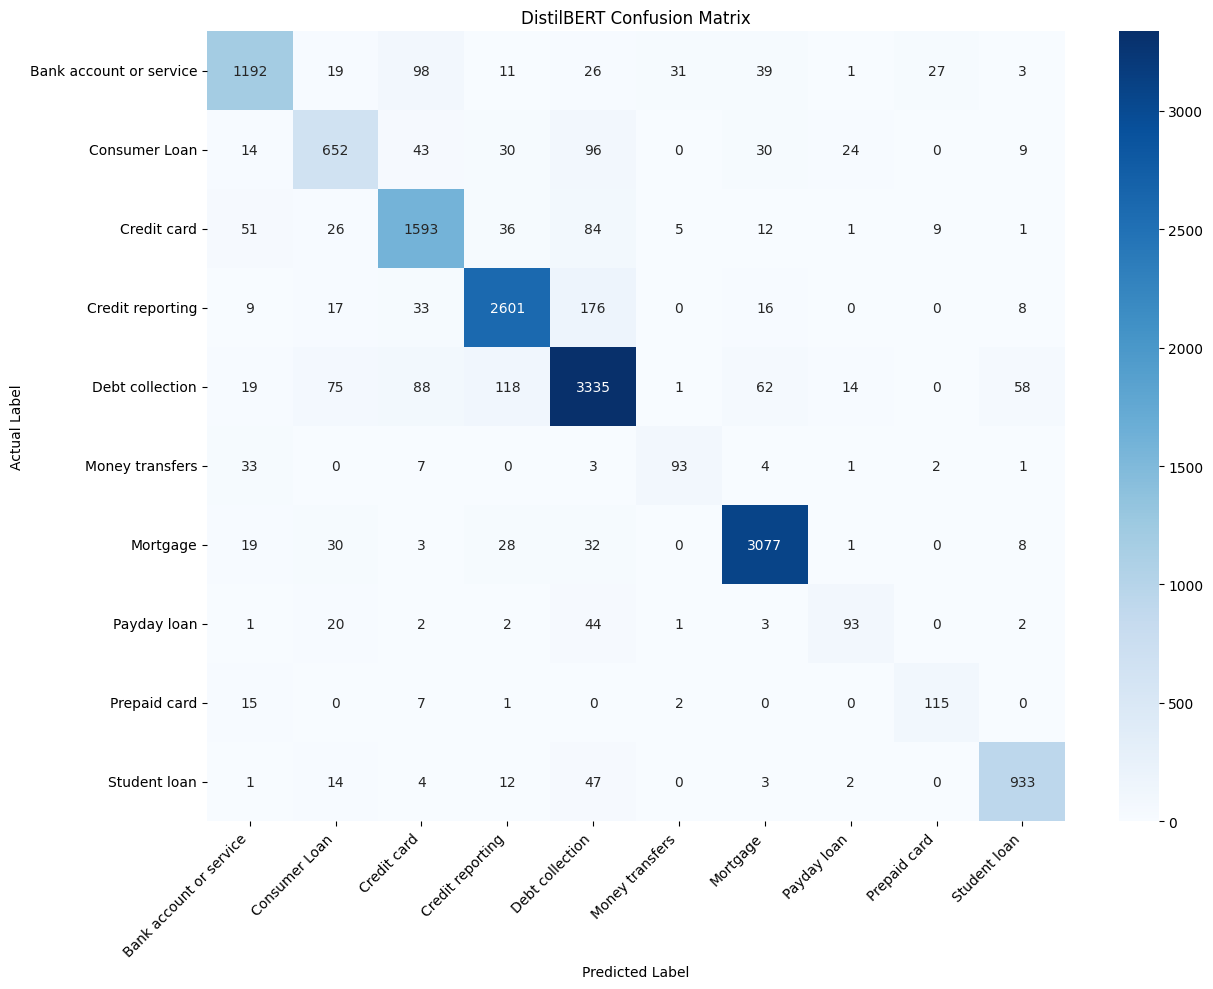

In [48]:
cm = confusion_matrix(
    y_test_encoded,
    bert_predictions
)

plt.figure(figsize=(13, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("DistilBERT Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [49]:
def predict_complaint(text):
    bert_trainer.model.eval()

    inputs = bert_tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH
    )

    device = next(bert_trainer.model.parameters()).device
    inputs = {key: value.to(device) for key, value in inputs.items()}

    with torch.no_grad():
        outputs = bert_trainer.model(**inputs)
        probabilities = torch.softmax(outputs.logits, dim=1)[0]

    predicted_index = torch.argmax(probabilities).item()
    predicted_label = label_encoder.inverse_transform([predicted_index])[0]
    confidence = probabilities[predicted_index].item()

    return predicted_label, confidence, {
        label_encoder.classes_[i]: float(probabilities[i])
        for i in range(num_classes)
    }

sample_text = "I was charged an incorrect amount on my credit card and the bank has not resolved the issue."

label, confidence, probabilities = predict_complaint(sample_text)

print("Predicted Category:", label)
print("Confidence:", f"{confidence:.2%}")
print("Probabilities:", probabilities)

Predicted Category: Credit card
Confidence: 93.29%
Probabilities: {'Bank account or service': 0.029731053858995438, 'Consumer Loan': 0.004823522642254829, 'Credit card': 0.9328869581222534, 'Credit reporting': 0.022229069843888283, 'Debt collection': 0.006141641177237034, 'Money transfers': 0.0003575070295482874, 'Mortgage': 0.0014753342838957906, 'Payday loan': 0.0003954267594963312, 'Prepaid card': 0.0012644210364669561, 'Student loan': 0.0006952055264264345}


In [56]:
import html
import torch
import gradio as gr
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# ====== Config ======
MODEL_PATH = "/kaggle/working/distilbert_model"
MAX_LEN = 256
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_PATH,
    local_files_only=True
)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_PATH,
    local_files_only=True
).to(DEVICE).eval()

id2label = model.config.id2label
# ====== Prediction ======
def predict_complaint(text):
    inputs = tokenizer(text, return_tensors="pt", truncation=True,
                       max_length=MAX_LEN, padding=True).to(DEVICE)
    with torch.no_grad():
        probs = torch.softmax(model(**inputs).logits, dim=-1)[0].cpu().tolist()
    probabilities = {id2label[i]: p for i, p in enumerate(probs)}
    label = max(probabilities, key=probabilities.get)
    return label, probabilities[label], probabilities


def result_card(label, conf):
    if conf >= 0.75:
        color, level = "#16a34a", "High confidence"
    elif conf >= 0.5:
        color, level = "#d97706", "Medium confidence"
    else:
        color, level = "#dc2626", "Low confidence"
    return f"""
    <div class="card">
        <div class="card-title">Predicted Category</div>
        <div class="card-label">{html.escape(label)}</div>
        <div class="bar-bg"><div class="bar-fill" style="width:{conf*100:.1f}%;background:{color}"></div></div>
        <div class="card-meta">
            <span style="color:{color};font-weight:700">{conf*100:.1f}%</span>
            <span class="badge" style="background:{color}20;color:{color}">{level}</span>
        </div>
    </div>"""


def classify_complaint(text):
    if not text or not text.strip():
        return ("<div class='card empty'>✍️ Please enter a complaint to classify.</div>", None)
    label, conf, probs = predict_complaint(text)
    return result_card(label, conf), probs


# ====== UI ======
CSS = """
.gradio-container {max-width: 1100px !important; margin: auto;}
.header {text-align:center; padding: 28px 16px; border-radius: 16px;
         background: linear-gradient(135deg,#4f46e5,#7c3aed); color:white; margin-bottom:16px;}
.header h1 {margin:0; font-size:2rem; color:white;}
.header p {margin:6px 0 0; opacity:.9;}
.card {border:1px solid #e5e7eb; border-radius:16px; padding:22px; background:var(--background-fill-primary);
       box-shadow:0 4px 14px rgba(0,0,0,.06);}
.card.empty {text-align:center; color:#6b7280;}
.card-title {font-size:.8rem; text-transform:uppercase; letter-spacing:.08em; color:#6b7280;}
.card-label {font-size:1.5rem; font-weight:800; margin:6px 0 14px; color:#4f46e5;}
.bar-bg {height:12px; background:#e5e7eb; border-radius:999px; overflow:hidden;}
.bar-fill {height:100%; border-radius:999px; transition:width .6s ease;}
.card-meta {display:flex; justify-content:space-between; align-items:center; margin-top:10px;}
.badge {padding:3px 12px; border-radius:999px; font-size:.8rem; font-weight:600;}
footer {display:none !important;}
"""

theme = gr.themes.Soft(primary_hue="indigo", secondary_hue="violet", neutral_hue="slate")

EXAMPLES = [
    ["I found an unauthorized charge on my credit card and the bank refuses to refund it."],
    ["My mortgage servicer keeps misapplying my payments and charging late fees."],
    ["A debt collector keeps calling me about a debt that is not mine."],
    ["There is an incorrect account on my credit report that I already disputed twice."],
]

with gr.Blocks(theme=theme, css=CSS, title="Consumer Complaint Classifier") as demo:
    gr.HTML("""<div class="header">
                 <h1>🏦 Consumer Complaint Classifier</h1>
                 <p>AI-powered financial complaint classification using DistilBERT</p>
               </div>""")

    with gr.Row(equal_height=False):
        with gr.Column(scale=5):
            inp = gr.Textbox(lines=9, label="Consumer Complaint",
                             placeholder="Describe your financial complaint...")
            with gr.Row():
                clear_btn = gr.Button("Clear", variant="secondary")
                submit_btn = gr.Button("Classify 🚀", variant="primary")
            gr.Examples(EXAMPLES, inputs=inp, label="Try an example")

        with gr.Column(scale=5):
            out_card = gr.HTML(value="<div class='card empty'>Results will appear here.</div>")
            out_probs = gr.Label(label="Class Probabilities", num_top_classes=10)

    submit_btn.click(classify_complaint, inp, [out_card, out_probs])
    inp.submit(classify_complaint, inp, [out_card, out_probs])
    clear_btn.click(lambda: ("", "<div class='card empty'>Results will appear here.</div>", None),
                    None, [inp, out_card, out_probs])

if __name__ == "__main__":
    demo.launch(share=True)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

/tmp/ipykernel_48/3685212320.py:87: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=theme, css=CSS, title="Consumer Complaint Classifier") as demo:


* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://0d6231c8721095ffd3.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [55]:
import os

paths = [
    "/kaggle/working/final_artifacts",
    "/kaggle/working/final_artifacts/distilbert_model",
    "/kaggle/working"
]

for path in paths:
    print("\nPath:", path)
    print("Exists:", os.path.exists(path))

    if os.path.exists(path):
        print("Contents:", os.listdir(path))


Path: /kaggle/working/final_artifacts
Exists: False

Path: /kaggle/working/final_artifacts/distilbert_model
Exists: False

Path: /kaggle/working
Exists: True
Contents: ['simple_rnn.keras', '.virtual_documents', 'distilbert_results', 'lstm.keras', 'gru.keras', 'simple_rnn_v2.keras', 'artifacts', 'distilbert_model', 'simple_rnn_results.json']
